# Superstore Sales Analysis

Analysis of the Sample Superstore dataset (orders from 2014 to 2017) for the CodeNova Data Science internship, Task 1.

**Goal:** calculate the key business metrics (revenue, profit margin, AOV, units), examine trends and seasonality, and find which categories, regions and discount levels drive or hurt profit.

**Tools:** Python, pandas, matplotlib.

In [24]:
%pip install pandas matplotlib seaborn openpyxl xlrd

Note: you may need to restart the kernel to use updated packages.


## 1. Data loading

**Question:** is the data complete and in the right format before we analyse it?

In [25]:
import pandas as pd
from pathlib import Path

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

path = r"C:\Users\adamo\OneDrive\Desktop\superstore-sales-analyst\data\Sample - Superstore.xls"
df = pd.read_excel(path)

print(df.shape)
print(df.head())
print(df.info())
print(df.describe())
df.head()

(9994, 21)
   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688 2016-06-12 2016-06-16    Second Class    DV-13045   
3       4  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   
4       5  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   South

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 2. Overall business metrics

**Question:** how is the business doing overall?

In [26]:
total_revenue=df["Sales"].sum()

total_profit=df["Profit"].sum()

profit_margin=total_profit/total_revenue

n_orders = df["Order ID"].nunique()

aov = total_revenue/n_orders

total_units_sold = df["Quantity"].sum()

print("Συνολικά έσοδα:", round(total_revenue, 2))
print("Συνολικό κέρδος:", round(total_profit, 2))
print("Profit margin:", round(profit_margin * 100, 1), "%")
print("Παραγγελίες:", n_orders)
print("AOV:", round(aov, 2))
print("Τεμάχια:", total_units_sold)

Συνολικά έσοδα: 2297200.86
Συνολικό κέρδος: 286397.02
Profit margin: 12.5 %
Παραγγελίες: 5009
AOV: 458.61
Τεμάχια: 37873


## 3. Trends over time

**Question:** how do revenue, profit and AOV change from year to year, quarter to quarter and month to month?

### Yearly

                Sales    Profit  Profit Margin  Orders     AOV  Units Sold
Order Date                                                                
2014        484247.50  49543.97           0.10     969  499.74        7581
2015        470532.51  61618.60           0.13    1038  453.31        7979
2016        609205.60  81795.17           0.13    1315  463.27        9837
2017        733215.26  93439.27           0.13    1687  434.63       12476


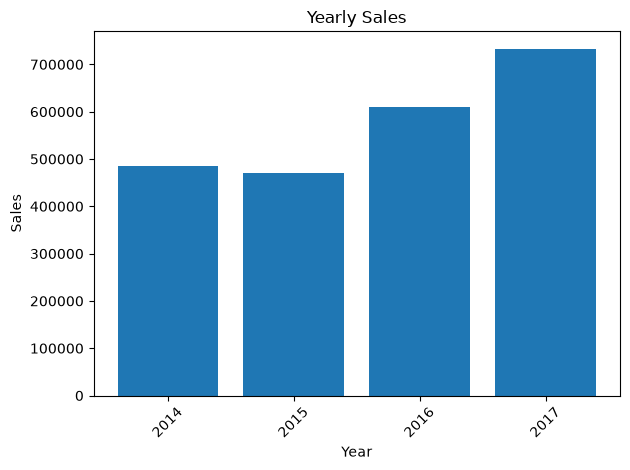

In [27]:
yearly_sales=df.groupby(df["Order Date"].dt.year)["Sales"].sum()

yearly_profit=df.groupby(df["Order Date"].dt.year)["Profit"].sum()
yearly_profit_margin=yearly_profit/yearly_sales

yearly_orders = df.groupby(df["Order Date"].dt.year)["Order ID"].nunique()
yearly_AOV = yearly_sales / yearly_orders

yearly_units_sold = df.groupby(df["Order Date"].dt.year)["Quantity"].sum()

yearly_table=pd.DataFrame({
    "Sales": yearly_sales, 
    "Profit": yearly_profit,
    "Profit Margin": yearly_profit_margin,
    "Orders": yearly_orders,
    "AOV": yearly_AOV,
    "Units Sold": yearly_units_sold
})
print(yearly_table.round(2))

from matplotlib import pyplot as plt
plt.bar(yearly_sales.index, yearly_sales.values)
plt.xlabel("Year")
plt.ylabel("Sales")
plt.title("Yearly Sales")
plt.xticks(yearly_sales.index, rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "yearly_sales.png", dpi=300, bbox_inches="tight")
plt.show()


import numpy as np

assert np.isclose(yearly_sales.sum(), total_revenue)
assert yearly_orders.sum() == n_orders
assert yearly_units_sold.sum() == total_units_sold






### Quarterly

                Sales    Profit  Profit Margin  Orders     AOV  Units Sold
Order Date                                                                
2014Q1       74447.80   3811.23           0.05     131  568.30        1028
2014Q2       86538.76  11204.07           0.13     201  430.54        1523
2014Q3      143633.21  12804.72           0.09     267  537.95        2159
2014Q4      179627.73  21723.95           0.12     370  485.48        2871
2015Q1       68851.74   9264.94           0.13     144  478.14         990
2015Q2       89124.19  12190.92           0.14     214  416.47        1604
2015Q3      130259.58  16853.62           0.13     274  475.40        2241
2015Q4      182297.01  23309.12           0.13     406  449.01        3144
2016Q1       93237.18  11441.37           0.12     179  520.88        1243
2016Q2      136082.30  16390.34           0.12     294  462.86        2240
2016Q3      143787.36  15823.60           0.11     378  380.39        2767
2016Q4      236098.75  38

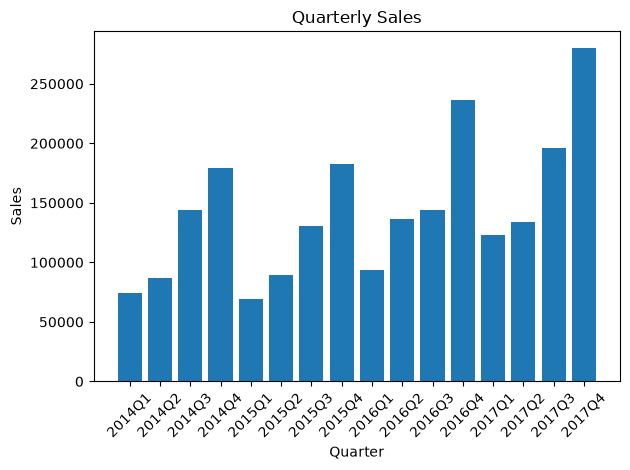

In [28]:
monthly3_sales=df.groupby(df["Order Date"].dt.to_period("Q"))["Sales"].sum()

monthly3_profit=df.groupby(df["Order Date"].dt.to_period("Q"))["Profit"].sum()
monthly3_profit_margin=monthly3_profit/monthly3_sales

monthly3_orders = df.groupby(df["Order Date"].dt.to_period("Q"))["Order ID"].nunique()
monthly3_AOV = monthly3_sales / monthly3_orders

monthly3_units_sold = df.groupby(df["Order Date"].dt.to_period("Q"))["Quantity"].sum()

monthly3_table=pd.DataFrame({
    "Sales": monthly3_sales, 
    "Profit": monthly3_profit,
    "Profit Margin": monthly3_profit_margin,
    "Orders": monthly3_orders,
    "AOV": monthly3_AOV,
    "Units Sold": monthly3_units_sold
})
print(monthly3_table.round(2))

from matplotlib import pyplot as plt
plt.bar(monthly3_sales.index.astype(str), monthly3_sales.values)
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.title("Quarterly Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "quarterly_sales.png", dpi=300, bbox_inches="tight")
plt.show()


import numpy as np
assert np.isclose(monthly3_sales.sum(), total_revenue)
assert monthly3_orders.sum() == n_orders
assert monthly3_units_sold.sum() == total_units_sold

### Monthly

                Sales    Profit  Profit Margin  Orders     AOV  Units Sold
Order Date                                                                
2014-01      14236.90   2450.19           0.17      32  444.90         284
2014-02       4519.89    862.31           0.19      28  161.42         159
2014-03      55691.01    498.73           0.01      71  784.38         585
2014-04      28295.34   3488.84           0.12      66  428.72         536
2014-05      23648.29   2738.71           0.12      69  342.73         466
2014-06      34595.13   4976.52           0.14      66  524.17         521
2014-07      33946.39   -841.48          -0.02      65  522.25         550
2014-08      27909.47   5318.10           0.19      72  387.63         609
2014-09      81777.35   8328.10           0.10     130  629.06        1000
2014-10      31453.39   3448.26           0.11      78  403.25         573
2014-11      78628.72   9292.13           0.12     151  520.72        1219
2014-12      69545.62   8

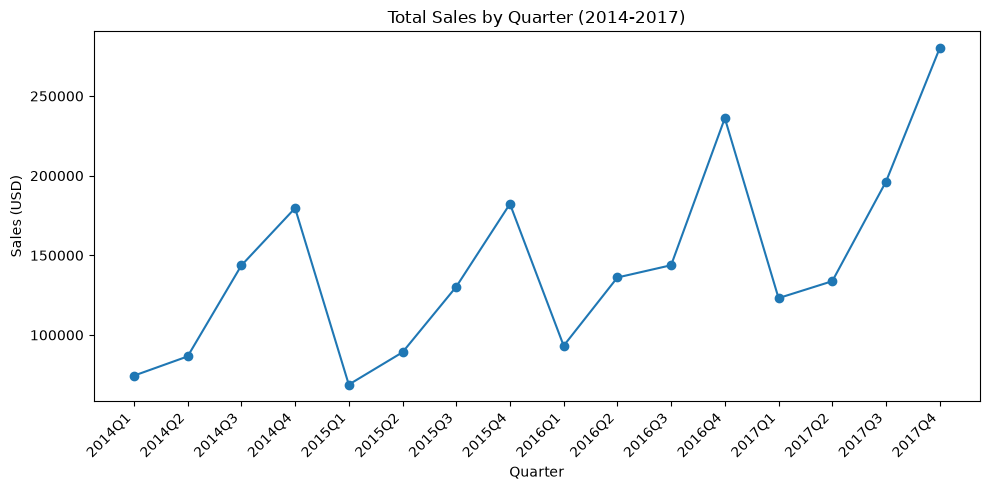

In [29]:
monthly_sales=df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()

monthly_profit=df.groupby(df["Order Date"].dt.to_period("M"))["Profit"].sum()
monthly_profit_margin=monthly_profit/monthly_sales

monthly_orders = df.groupby(df["Order Date"].dt.to_period("M"))["Order ID"].nunique()
monthly_AOV = monthly_sales / monthly_orders

monthly_units_sold = df.groupby(df["Order Date"].dt.to_period("M"))["Quantity"].sum()

monthly_table=pd.DataFrame({
    "Sales": monthly_sales,
    "Profit": monthly_profit,
    "Profit Margin": monthly_profit_margin,
    "Orders": monthly_orders,
    "AOV": monthly_AOV,
    "Units Sold": monthly_units_sold
})
print(monthly_table.round(2))

from matplotlib import pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(monthly3_sales.index.astype(str), monthly3_sales.values, marker="o")
plt.xlabel("Quarter")
plt.ylabel("Sales (USD)")
plt.title("Total Sales by Quarter (2014-2017)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "monthly_sales.png", dpi=300, bbox_inches="tight")
plt.show()

import numpy as np
assert np.isclose(monthly_sales.sum(), total_revenue)
assert monthly_orders.sum() == n_orders
assert monthly_units_sold.sum() == total_units_sold

## 4. Seasonality

**Question:** which months of the year are consistently strong or weak?

                Sales    Profit  Profit Margin  Orders     AOV  Units Sold
Order Date                                                                
1            94924.84   9134.45           0.10     178  533.29        1475
2            59751.25  10294.61           0.17     162  368.83        1067
3           205005.49  28594.69           0.14     354  579.11        2564
4           137762.13  11587.44           0.08     343  401.64        2447
5           155028.81  22411.31           0.14     369  420.13        2791
6           152718.68  21285.80           0.14     364  419.56        2680
7           147238.10  13832.66           0.09     338  435.62        2705
8           159044.06  21776.94           0.14     341  466.40        2784
9           307649.95  36857.48           0.12     688  447.17        5062
10          200322.98  31784.04           0.16     417  480.39        3104
11          352461.07  35468.43           0.10     753  468.08        5775
12          325293.50  43

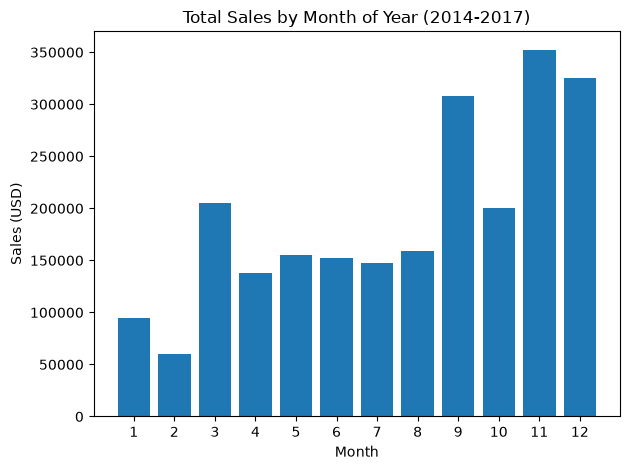

In [30]:
from matplotlib import pyplot as plt


seasonal_sales=df.groupby(df["Order Date"].dt.month)["Sales"].sum()
seasonal_profit=df.groupby(df["Order Date"].dt.month)["Profit"].sum()
seasonal_profit_margin=seasonal_profit/seasonal_sales

seasonal_orders = df.groupby(df["Order Date"].dt.month)["Order ID"].nunique()
seasonal_AOV = seasonal_sales / seasonal_orders

seasonal_units_sold = df.groupby(df["Order Date"].dt.month)["Quantity"].sum()

seasonal_table=pd.DataFrame({
    "Sales": seasonal_sales,
    "Profit": seasonal_profit,
    "Profit Margin": seasonal_profit_margin,
    "Orders": seasonal_orders,
    "AOV": seasonal_AOV,
    "Units Sold": seasonal_units_sold
})
print(seasonal_table.round(2))

plt.bar(seasonal_sales.index, seasonal_sales.values)
plt.xlabel("Month")
plt.ylabel("Sales (USD)")
plt.title("Total Sales by Month of Year (2014-2017)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.savefig(FIG_DIR / "seasonal_sales.png", dpi=300, bbox_inches="tight")
plt.show()


import numpy as np
assert np.isclose(seasonal_sales.sum(), total_revenue)
assert seasonal_orders.sum() == n_orders
assert seasonal_units_sold.sum() == total_units_sold



## 5. Category performance

**Question:** which categories sell the most, and which have the best margin?

                     Sales     Profit  Profit Margin  Orders     AOV  \
Category                                                               
Furniture        741999.80   18451.27           0.02    1764  420.63   
Office Supplies  719047.03  122490.80           0.17    3742  192.16   
Technology       836154.03  145454.95           0.17    1544  541.55   

                 Units Sold  
Category                     
Furniture              8028  
Office Supplies       22906  
Technology             6939  


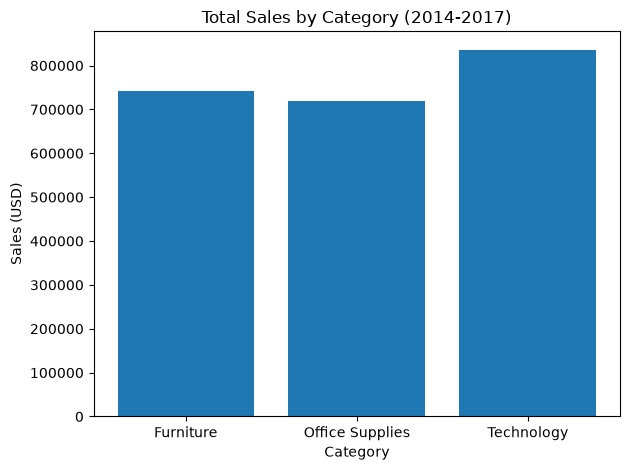

In [31]:
category_sales=df.groupby(df["Category"])["Sales"].sum()
category_profit=df.groupby(df["Category"])["Profit"].sum()
category_profit_margin=category_profit/category_sales

category_orders = df.groupby(df["Category"])["Order ID"].nunique()
category_AOV = category_sales / category_orders

category_units_sold = df.groupby(df["Category"])["Quantity"].sum()

category_table=pd.DataFrame({
    "Sales": category_sales,
    "Profit": category_profit,
    "Profit Margin": category_profit_margin,
    "Orders": category_orders,
    "AOV": category_AOV,
    "Units Sold": category_units_sold
})
print(category_table.round(2))

from matplotlib import pyplot as plt
plt.bar(category_sales.index, category_sales.values)
plt.xlabel("Category")
plt.ylabel("Sales (USD)")
plt.title("Total Sales by Category (2014-2017)")
plt.tight_layout()
plt.savefig(FIG_DIR / "category_sales.png", dpi=300, bbox_inches="tight")
plt.show()

import numpy as np
assert np.isclose(category_sales.sum(), total_revenue)
assert category_units_sold.sum() == total_units_sold



### Sub-categories

**Question:** which sub-categories sell a lot but lose money?

In [32]:
category_table.sort_values("Sales", ascending=False)           
category_table.sort_values("Profit Margin", ascending=False)

,Sales,Profit,Profit Margin,Orders,AOV,Units Sold
Category,,,,,,
Technology,836154.0330,145454.9481,0.173957,1544,541.550540,6939
Office Supplies,719047.0320,122490.8008,0.170352,3742,192.155808,22906
Furniture,741999.7953,18451.2728,0.024867,1764,420.634805,8028


                  Sales    Profit  Profit Margin  Orders      AOV  Units Sold
Sub-Category                                                                 
Accessories   167380.32  41936.64           0.25     718   233.12        2976
Appliances    107532.16  18138.01           0.17     451   238.43        1729
Art            27118.79   6527.79           0.24     731    37.10        3000
Binders       203412.73  30221.76           0.15    1316   154.57        5974
Bookcases     114880.00  -3472.56          -0.03     224   512.86         868
Chairs        328449.10  26590.17           0.08     576   570.22        2356
Copiers       149528.03  55617.82           0.37      68  2198.94         234
Envelopes      16476.40   6964.18           0.42     249    66.17         906
Fasteners       3024.28    949.52           0.31     215    14.07         914
Furnishings    91705.16  13059.14           0.14     877   104.57        3563
Labels         12486.31   5546.25           0.44     346    36.0

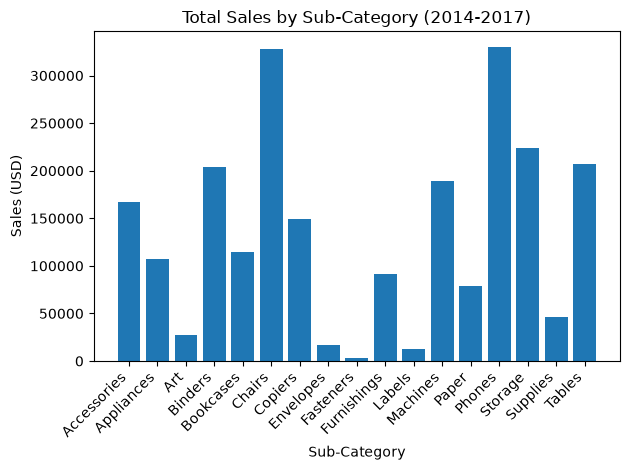

In [33]:
sub_category_sales=df.groupby(df["Sub-Category"])["Sales"].sum()
sub_category_profit=df.groupby(df["Sub-Category"])["Profit"].sum()
sub_category_profit_margin=sub_category_profit/sub_category_sales
sub_category_orders = df.groupby(df["Sub-Category"])["Order ID"].nunique()
sub_category_AOV = sub_category_sales / sub_category_orders

sub_category_units_sold = df.groupby(df["Sub-Category"])["Quantity"].sum()

sub_category_table=pd.DataFrame({
    "Sales": sub_category_sales,
    "Profit": sub_category_profit,
    "Profit Margin": sub_category_profit_margin,
    "Orders": sub_category_orders,
    "AOV": sub_category_AOV,
    "Units Sold": sub_category_units_sold
})
print(sub_category_table.round(2))

from matplotlib import pyplot as plt
plt.bar(sub_category_sales.index, sub_category_sales.values)
plt.xlabel("Sub-Category")
plt.ylabel("Sales (USD)")
plt.title("Total Sales by Sub-Category (2014-2017)")
plt.xticks(rotation=45 , ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "sub_category_sales.png", dpi=300, bbox_inches="tight")
plt.show()


import numpy as np
assert np.isclose(sub_category_sales.sum(), total_revenue)
assert sub_category_units_sold.sum() == total_units_sold


In [34]:
sub_category_table.sort_values("Profit Margin")

,Sales,Profit,Profit Margin,Orders,AOV,Units Sold
Sub-Category,,,,,,
Tables,206965.5320,-17725.4811,-0.085645,307,674.154827,1241
Bookcases,114879.9963,-3472.5560,-0.030228,224,512.857126,868
Supplies,46673.5380,-1189.0995,-0.025477,187,249.591112,647
Machines,189238.6310,3384.7569,0.017886,112,1689.630634,440
Chairs,328449.1030,26590.1663,0.080957,576,570.224137,2356
Storage,223843.6080,21278.8264,0.095061,777,288.087012,3158
Phones,330007.0540,44515.7306,0.134893,814,405.414071,3289
Furnishings,91705.1640,13059.1436,0.142404,877,104.566892,3563
Binders,203412.7330,30221.7633,0.148574,1316,154.568946,5974


             Sales     Profit  Profit Margin  Orders     AOV  Units Sold
Region                                                                  
Central  501239.89   39706.36           0.08    1175  426.59        8780
East     678781.24   91522.78           0.13    1401  484.50       10618
South    391721.90   46749.43           0.12     822  476.55        6209
West     725457.82  108418.45           0.15    1611  450.32       12266


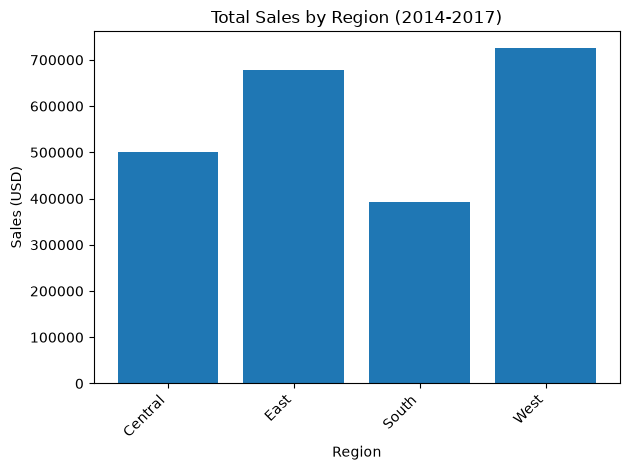

In [35]:
region_sales=df.groupby(df["Region"])["Sales"].sum()
region_profit=df.groupby(df["Region"])["Profit"].sum()
region_profit_margin=region_profit/region_sales
region_orders = df.groupby(df["Region"])["Order ID"].nunique()
region_AOV = region_sales / region_orders

regiion_units_sold = df.groupby(df["Region"])["Quantity"].sum()
region_table=pd.DataFrame({
    "Sales": region_sales,
    "Profit": region_profit,
    "Profit Margin": region_profit_margin,
    "Orders": region_orders,
    "AOV": region_AOV,
    "Units Sold": regiion_units_sold
})
print (region_table.round(2))

from matplotlib import pyplot as plt
plt.bar(region_sales.index, region_sales.values)
plt.xlabel("Region")
plt.ylabel("Sales (USD)")
plt.title("Total Sales by Region (2014-2017)")
plt.xticks(rotation=45 , ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "region_sales.png", dpi=300, bbox_inches="tight")
plt.show()

import numpy as np
assert np.isclose(region_sales.sum(), total_revenue)
assert regiion_units_sold.sum() == total_units_sold
assert region_orders.sum() == n_orders

## 6. The role of discounts

**Question:** do discounts explain the losses?

Discount
0.00    320987.60
0.10      9029.18
0.15      1418.99
0.20     90337.31
0.30    -10369.28
0.32     -2391.14
0.40    -23057.05
0.45     -2493.11
0.50    -20506.43
0.60     -5944.66
0.70    -40075.36
0.80    -30539.04
Name: Profit, dtype: float64


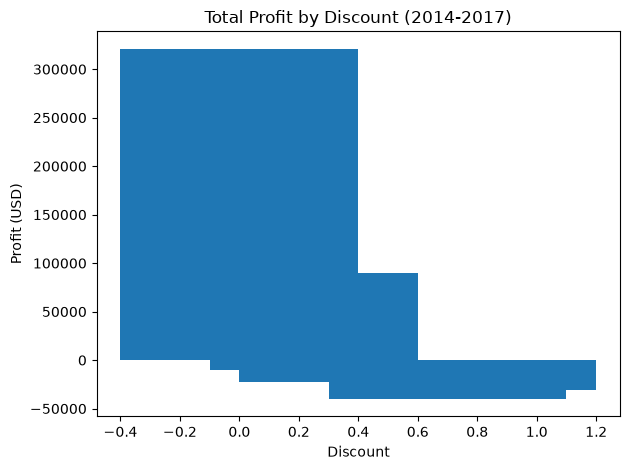

In [36]:
discount_profit = df.groupby(df["Discount"])["Profit"].sum()
print(discount_profit.round(2))

discount_profit_table = pd.DataFrame({
    "Profit": discount_profit
})

from matplotlib import pyplot as plt
plt.bar(discount_profit.index, discount_profit.values)
plt.xlabel("Discount")
plt.ylabel("Profit (USD)")
plt.title("Total Profit by Discount (2014-2017)")
plt.tight_layout()
plt.savefig(FIG_DIR / "discount_profit.png", dpi=300, bbox_inches="tight")
plt.show()








Sub-Category
Accessories    0.08
Appliances     0.17
Art            0.07
Binders        0.37
Bookcases      0.21
Chairs         0.17
Copiers        0.16
Envelopes      0.08
Fasteners      0.08
Furnishings    0.14
Labels         0.07
Machines       0.31
Paper          0.07
Phones         0.15
Storage        0.07
Supplies       0.08
Tables         0.26
Name: Discount, dtype: float64


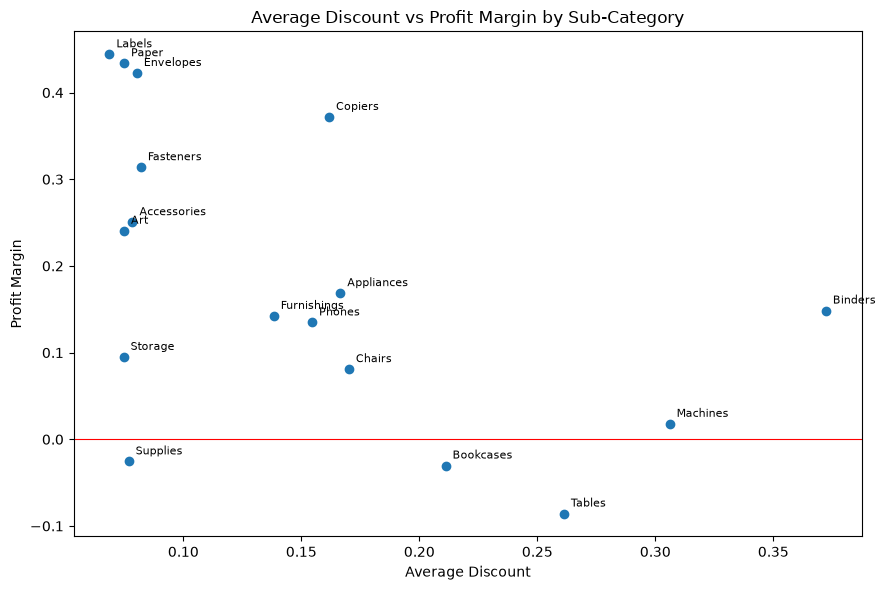

In [37]:
sub_category_discount = df.groupby("Sub-Category")["Discount"].mean()
print(sub_category_discount.round(2))

sub_category_table["Avg Discount"] = sub_category_discount
from matplotlib import pyplot as plt
plt.figure(figsize=(9, 6))
plt.scatter(sub_category_table["Avg Discount"], sub_category_table["Profit Margin"])

for name, row in sub_category_table.iterrows():
    plt.annotate(name, (row["Avg Discount"], row["Profit Margin"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)

plt.axhline(0, color="red", linewidth=0.8)
plt.xlabel("Average Discount")
plt.ylabel("Profit Margin")
plt.title("Average Discount vs Profit Margin by Sub-Category")
plt.tight_layout()
plt.savefig(FIG_DIR / "sub_category_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Geography

**Question:** where do we sell the most, and where do we lose money?

### Regions

                          Sales    Profit  Profit Margin  Orders      AOV  \
State                                                                       
Alabama                19510.64   5786.83           0.30      34   573.84   
Arizona                35282.00  -3427.92          -0.10     108   326.69   
Arkansas               11678.13   4008.69           0.34      27   432.52   
California            457687.63  76381.39           0.17    1021   448.27   
Colorado               32108.12  -6527.86          -0.20      79   406.43   
Connecticut            13384.36   3511.49           0.26      45   297.43   
Delaware               27451.07   9977.37           0.36      44   623.89   
District of Columbia    2865.02   1059.59           0.37       4   716.26   
Florida                89473.71  -3399.30          -0.04     200   447.37   
Georgia                49095.84  16250.04           0.33      91   539.51   
Idaho                   4382.49    826.72           0.19      11   398.41   

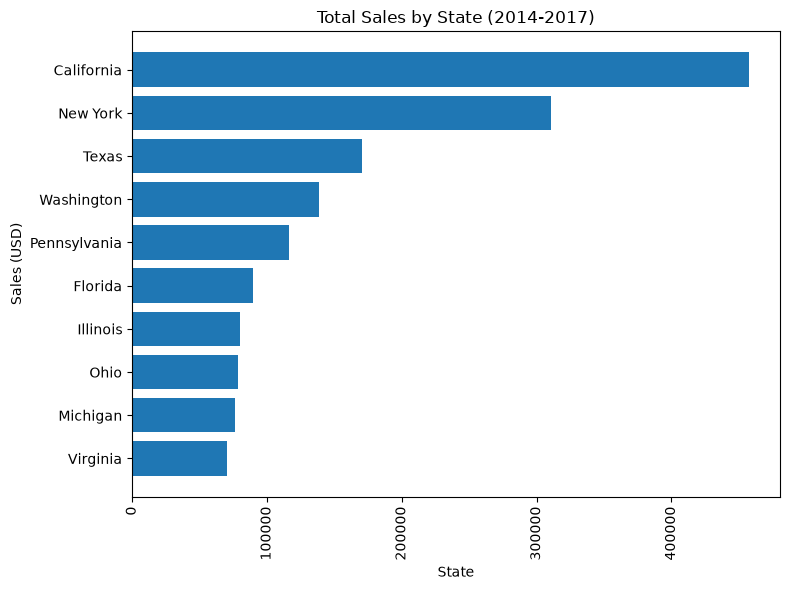

In [38]:
state_sales=df.groupby(df["State"])["Sales"].sum()
state_profit=df.groupby(df["State"])["Profit"].sum()
state_profit_margin=state_profit/state_sales
state_orders = df.groupby(df["State"])["Order ID"].nunique()
state_AOV = state_sales / state_orders
state_units_sold = df.groupby(df["State"])["Quantity"].sum()
state_table=pd.DataFrame({
    "Sales": state_sales,
    "Profit": state_profit,
    "Profit Margin": state_profit_margin,
    "Orders": state_orders,
    "AOV": state_AOV,
    "Units Sold": state_units_sold
})
print(state_table.round(2))

from matplotlib import pyplot as plt
top_states = state_sales.sort_values().tail(10)
plt.figure(figsize=(8, 6))
plt.barh(top_states.index, top_states.values)
plt.xlabel("State")
plt.ylabel("Sales (USD)")
plt.title("Total Sales by State (2014-2017)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(FIG_DIR / "state_sales.png", dpi=300, bbox_inches="tight")
plt.show()

import numpy as np
assert np.isclose(state_sales.sum(), total_revenue)
assert state_units_sold.sum() == total_units_sold
assert state_orders.sum() == n_orders


### Discount Profit

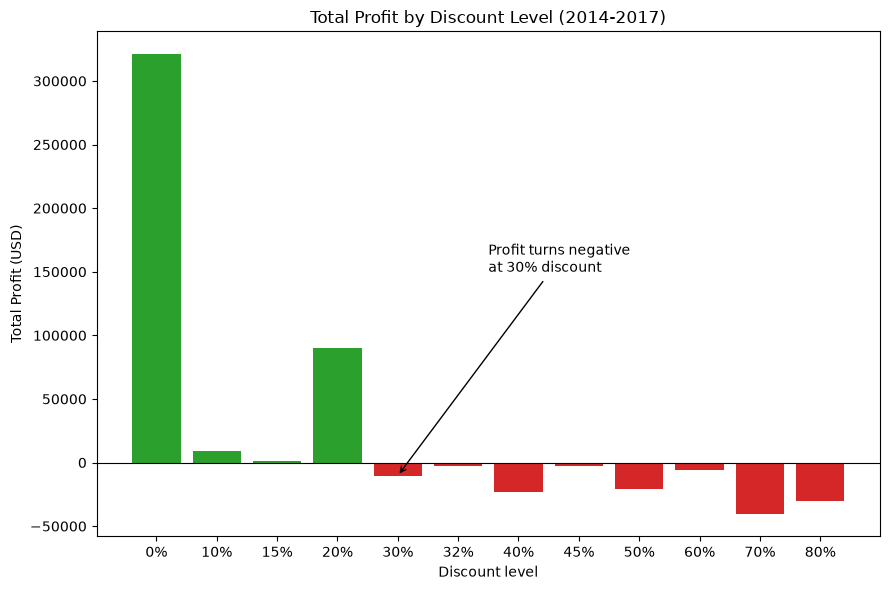

In [39]:
discount_profit=df.groupby(df["Discount"])["Profit"].sum()
discount_profit_table = pd.DataFrame({
    "Profit": discount_profit
})

from matplotlib import pyplot as plt
labels = (discount_profit.index * 100).round().astype(int).astype(str) + "%"
colors = ["tab:green" if v >= 0 else "tab:red" for v in discount_profit.values]

plt.figure(figsize=(9, 6))
plt.bar(labels, discount_profit.values, color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Discount level")
plt.ylabel("Total Profit (USD)")
plt.title("Total Profit by Discount Level (2014-2017)")
plt.annotate("Profit turns negative\nat 30% discount",
             xy=(4, discount_profit.loc[0.30]), xytext=(5.5, 150000),
             arrowprops=dict(arrowstyle="->"))
plt.tight_layout()
plt.savefig(FIG_DIR / "discount_profit.png", dpi=300, bbox_inches="tight")
plt.show()
import numpy as np
assert np.isclose(discount_profit.sum(), total_profit)
assert discount_profit_table.shape[0] == df["Discount"].nunique()


In [40]:
state_table[state_table["Profit"] < 0].sort_values("Profit")

,Sales,Profit,Profit Margin,Orders,AOV,Units Sold
State,,,,,,
Texas,170188.0458,-25729.3563,-0.151182,487,349.462106,3724
Ohio,78258.1360,-16971.3766,-0.216864,236,331.602271,1759
Pennsylvania,116511.9140,-15559.9603,-0.133548,288,404.555257,2153
Illinois,80166.1010,-12607.8870,-0.157272,276,290.456888,1845
North Carolina,55603.1640,-7490.9122,-0.134721,136,408.846794,983
Colorado,32108.1180,-6527.8579,-0.203309,79,406.431873,693
Tennessee,30661.8730,-5341.6936,-0.174213,91,336.943659,681
Arizona,35282.0010,-3427.9246,-0.097158,108,326.685194,862
Florida,89473.7080,-3399.3017,-0.037992,200,447.368540,1379
